# 03 · Modelos predictivos por sexo

Clasificadores de depresión y ansiedad sobre la muestra de desarrollo, por separado en mujeres y hombres.

- Modelos: regresión logística, Random Forest, SVM (RBF), MLP y XGBoost, con hiperparámetros fijos.
- Referencia: clasificador constante (AUC = 0,5).
- Conjuntos: PREGUNTA1, PREGUNTA2, DELTA y P1+P2 (40 columnas).
- Validación: cada modelo se ajusta con todos los sujetos de su sexo y se evalúa con bootstrap .632+ (Efron y Tibshirani, 1997):
  - AUC aparente: evaluado en los mismos datos del ajuste (optimista).
  - AUC OOB: en cada réplica, evaluado en los sujetos no sorteados (pesimista).
  - AUC .632+: combinación de ambos según el sobreajuste; vale 0,5 si el OOB no supera 0,5.
- Métricas OOB adicionales: exactitud balanceada, sensibilidad y especificidad.
- La prueba final queda sellada (sección 7).

## Housekeeping

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from joblib import Parallel, delayed

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_auc_score, balanced_accuracy_score, recall_score,
                             confusion_matrix, classification_report)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

import warnings
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

%matplotlib inline

In [2]:
# Parámetros
N_BOOT = 200           # réplicas bootstrap
SEMILLA = 2026
N_JOBS = 10            # procesos en paralelo
N_PERMUTACIONES = 100  # 0 = no correr
N_BOOT_PERM = 50       # réplicas por permutación

datos = pd.read_csv("outputs/desarrollo.csv", dtype={"participant_id": str})
SEXOS = ["mujer", "hombre"]
OBJETIVOS = {"dep": "Depresión (PHQ-9 ≥ 10)", "ans": "Ansiedad (GAD-7 ≥ 10)"}
FEATURES = [c.split("__")[0] for c in datos.columns if c.endswith("__DELTA")]

CONJUNTOS = {c: [f"{f}__{c}" for f in FEATURES] for c in ["PREGUNTA1", "PREGUNTA2", "DELTA"]}
CONJUNTOS["P1+P2"] = CONJUNTOS["PREGUNTA1"] + CONJUNTOS["PREGUNTA2"]
METRICAS = ["auc", "bal_acc", "sens", "esp"]

def anotar(texto):
    """Imprime y escribe en outputs/predictivo_progreso.log."""
    print(texto)
    with open("outputs/predictivo_progreso.log", "a", encoding="utf-8") as f:
        f.write(f"{time.strftime('%Y-%m-%d %H:%M:%S')} {texto}\n")

POR_SEXO = {s: datos[datos["sexo"] == s].reset_index(drop=True) for s in SEXOS}

print(f"Features por tarea: {len(FEATURES)} | columnas por conjunto: { {k: len(v) for k, v in CONJUNTOS.items()} }")
for s, d_s in POR_SEXO.items():
    print(f"{s}: n = {len(d_s)} | " + " | ".join(f"{o}: {d_s[o].sum()} casos ({d_s[o].mean():.3f})" for o in OBJETIVOS))

Features por tarea: 20 | columnas por conjunto: {'PREGUNTA1': 20, 'PREGUNTA2': 20, 'DELTA': 20, 'P1+P2': 40}
mujer: n = 197 | dep: 97 casos (0.492) | ans: 70 casos (0.355)
hombre: n = 158 | dep: 42 casos (0.266) | ans: 35 casos (0.222)


## 1. Modelos

Pipeline: imputación por la mediana → estandarización → clasificador.

In [3]:
def modelos(y):
    peso_pos = (y == 0).sum() / (y == 1).sum()   # equivale a class_weight="balanced"
    return {
        "logreg": LogisticRegression(C=0.1, class_weight="balanced", max_iter=5000),
        "rf": RandomForestClassifier(n_estimators=300, max_depth=3, min_samples_leaf=5,
                                     class_weight="balanced_subsample", random_state=SEMILLA, n_jobs=1),
        "svm": SVC(kernel="rbf", C=1, gamma="scale", class_weight="balanced"),
        "mlp": MLPClassifier(hidden_layer_sizes=(16,), alpha=0.1, max_iter=2000, random_state=SEMILLA),
        "xgb": XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=2, min_child_weight=5,
                             subsample=0.8, colsample_bytree=0.8, scale_pos_weight=peso_pos,
                             eval_metric="logloss", random_state=SEMILLA, n_jobs=1),
    }

def pipeline(clf):
    return Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler()), ("modelo", clf)])

def puntaje(est, X):
    """Probabilidad, o función de decisión en la SVM."""
    return est.predict_proba(X)[:, 1] if hasattr(est, "predict_proba") else est.decision_function(X)

def medir(est, X, y):
    p, c = puntaje(est, X), est.predict(X)
    return {"auc": roc_auc_score(y, p), "bal_acc": balanced_accuracy_score(y, c),
            "sens": recall_score(y, c), "esp": recall_score(y, c, pos_label=0)}

for nombre_m, clf in modelos(POR_SEXO["mujer"]["dep"]).items():
    print(f"{nombre_m}: { {k: v for k, v in clf.get_params().items() if k in ['C', 'gamma', 'max_depth', 'min_samples_leaf', 'hidden_layer_sizes', 'alpha', 'min_child_weight', 'n_estimators']} }")

logreg: {'C': 0.1}
rf: {'max_depth': 3, 'min_samples_leaf': 5, 'n_estimators': 300}
svm: {'C': 1, 'gamma': 'scale'}
mlp: {'alpha': 0.1, 'hidden_layer_sizes': (16,)}
xgb: {'gamma': None, 'max_depth': 2, 'min_child_weight': 5, 'n_estimators': 200}


## 2. Bootstrap .632+

Réplicas estratificadas por desenlace, con las mismas semillas en todas las configuraciones.

- OOB' = máx(OOB, 0,5)
- R = (aparente − OOB') / (aparente − 0,5)
- w = 0,632 / (1 − 0,368 R)
- AUC .632+ = (1 − w) · aparente + w · OOB'

In [4]:
def remuestreo(y, rng):
    """Bootstrap estratificado por desenlace."""
    return np.concatenate([rng.choice(np.flatnonzero(y == k), size=(y == k).sum(), replace=True) for k in (0, 1)])

def replica(est, X, y, semilla):
    """Ajusta en la réplica y evalúa en los sujetos OOB."""
    rng = np.random.default_rng(semilla)
    idx = remuestreo(y.values, rng)
    oob = np.setdiff1d(np.arange(len(y)), idx)
    m = clone(est).fit(X.iloc[idx], y.iloc[idx])
    return medir(m, X.iloc[oob], y.iloc[oob]), oob, m.predict(X.iloc[oob])

def auc_632plus(aparente, oob):
    oob_ = max(oob, 0.5)
    r = (aparente - oob_) / (aparente - 0.5) if aparente > oob_ else 0.0
    w = 0.632 / (1 - 0.368 * r)
    return (1 - w) * aparente + w * oob_

def evaluar(est, X, y, n_boot=N_BOOT):
    t0 = time.time()
    aparente = medir(clone(est).fit(X, y), X, y)
    reps = Parallel(n_jobs=N_JOBS)(delayed(replica)(est, X, y, SEMILLA + b) for b in range(n_boot))
    por_replica = {k: np.array([r[k] for r, *_ in reps]) for k in METRICAS}
    oob = {k: v.mean() for k, v in por_replica.items()}
    votos, veces = np.zeros(len(y)), np.zeros(len(y))
    for _, i_oob, c in reps:
        votos[i_oob] += c; veces[i_oob] += 1
    oob_y = np.where(veces > 0, (votos / np.maximum(veces, 1) >= 0.5).astype(float), np.nan)
    return {"aparente": aparente, "oob": oob, "por_replica": por_replica,
            "auc_632": auc_632plus(aparente["auc"], oob["auc"]), "oob_y": oob_y, "seg": time.time() - t0}

resultados = {}
t_total = time.time()
for s, d_s in POR_SEXO.items():
    for obj in OBJETIVOS:
        y = d_s[obj]
        resultados[(s, obj, "referencia", "constante")] = evaluar(pipeline(DummyClassifier(strategy="prior")), d_s[CONJUNTOS["DELTA"]], y)
        for conj, cols in CONJUNTOS.items():
            for nombre_m, clf in modelos(y).items():
                r = evaluar(pipeline(clf), d_s[cols], y)
                resultados[(s, obj, conj, nombre_m)] = r
                anotar(f"{s:6s} | {obj} | {conj:9s} | {nombre_m:6s} | AUC aparente {r['aparente']['auc']:.3f} | "
                       f"OOB {r['oob']['auc']:.3f} ± {r['por_replica']['auc'].std():.3f} | .632+ {r['auc_632']:.3f} | {r['seg']:.0f} s")
anotar(f"Tiempo total del bootstrap: {(time.time() - t_total) / 60:.1f} min")

mujer  | dep | PREGUNTA1 | logreg | AUC aparente 0.643 | OOB 0.450 ± 0.053 | .632+ 0.500 | 1 s


mujer  | dep | PREGUNTA1 | rf     | AUC aparente 0.922 | OOB 0.467 ± 0.056 | .632+ 0.500 | 29 s


mujer  | dep | PREGUNTA1 | svm    | AUC aparente 0.881 | OOB 0.452 ± 0.052 | .632+ 0.500 | 1 s


mujer  | dep | PREGUNTA1 | mlp    | AUC aparente 1.000 | OOB 0.472 ± 0.053 | .632+ 0.500 | 27 s


mujer  | dep | PREGUNTA1 | xgb    | AUC aparente 0.978 | OOB 0.434 ± 0.053 | .632+ 0.500 | 5 s


mujer  | dep | PREGUNTA2 | logreg | AUC aparente 0.649 | OOB 0.477 ± 0.055 | .632+ 0.500 | 1 s


... (70 outputs left out)

hombre | ans | P1+P2     | rf     | AUC aparente 1.000 | OOB 0.469 ± 0.080 | .632+ 0.500 | 39 s


hombre | ans | P1+P2     | svm    | AUC aparente 0.996 | OOB 0.509 ± 0.075 | .632+ 0.514 | 1 s


hombre | ans | P1+P2     | mlp    | AUC aparente 1.000 | OOB 0.534 ± 0.085 | .632+ 0.551 | 14 s


hombre | ans | P1+P2     | xgb    | AUC aparente 1.000 | OOB 0.480 ± 0.078 | .632+ 0.500 | 3 s
Tiempo total del bootstrap: 13.9 min


## 3. Resultados

In [5]:
filas = []
for (s, obj, conj, mod), r in resultados.items():
    fila = {"sexo": s, "objetivo": obj, "conjunto": conj, "modelo": mod, "auc_632": r["auc_632"],
            "auc_aparente": r["aparente"]["auc"], "auc_oob": r["oob"]["auc"], "auc_oob_de": r["por_replica"]["auc"].std(),
            "auc_oob_sobre_0.5": (r["por_replica"]["auc"] > 0.5).mean()}
    for k in ["bal_acc", "sens", "esp"]:
        fila[f"{k}_oob"] = r["oob"][k]
    fila["segundos"] = r["seg"]
    filas.append(fila)
tabla = pd.DataFrame(filas)
modelos_voz = tabla[tabla["conjunto"].isin(list(CONJUNTOS))]
for s in SEXOS:
    for obj, nombre in OBJETIVOS.items():
        print(f"==================== {nombre} · {s}")
        display(tabla[(tabla["sexo"] == s) & (tabla["objetivo"] == obj)].drop(columns=["sexo", "objetivo"])
                .sort_values(["auc_632", "auc_oob"], ascending=False).round(3).reset_index(drop=True))

==================== Depresión (PHQ-9 ≥ 10) · mujer


,conjunto,modelo,auc_632,auc_aparente,auc_oob,auc_oob_de,auc_oob_sobre_0.5,bal_acc_oob,sens_oob,esp_oob,segundos
0,DELTA,mlp,0.564,1.000,0.543,0.058,0.745,0.532,0.520,0.543,21.554
1,DELTA,svm,0.553,0.913,0.535,0.053,0.730,0.516,0.507,0.524,1.038
2,PREGUNTA2,rf,0.543,0.948,0.528,0.065,0.690,0.525,0.526,0.523,27.431
3,PREGUNTA2,xgb,0.541,0.980,0.527,0.058,0.710,0.525,0.533,0.518,3.824
4,referencia,constante,0.500,0.500,0.500,0.000,0.000,0.500,0.000,1.000,4.915
5,P1+P2,rf,0.500,0.969,0.498,0.062,0.500,0.500,0.506,0.495,26.713
6,PREGUNTA2,svm,0.500,0.858,0.481,0.055,0.375,0.491,0.486,0.497,1.316
7,DELTA,logreg,0.500,0.661,0.481,0.056,0.390,0.488,0.479,0.497,1.120
8,PREGUNTA2,logreg,0.500,0.649,0.477,0.055,0.350,0.487,0.478,0.496,0.963
9,P1+P2,xgb,0.500,0.993,0.476,0.057,0.375,0.488,0.488,0.488,3.016


==================== Ansiedad (GAD-7 ≥ 10) · mujer


,conjunto,modelo,auc_632,auc_aparente,auc_oob,auc_oob_de,auc_oob_sobre_0.5,bal_acc_oob,sens_oob,esp_oob,segundos
0,DELTA,svm,0.536,0.907,0.523,0.050,0.670,0.512,0.407,0.617,1.604
1,PREGUNTA2,xgb,0.530,0.994,0.519,0.059,0.635,0.520,0.379,0.661,2.307
2,DELTA,mlp,0.507,1.000,0.504,0.058,0.525,0.512,0.334,0.690,20.940
3,PREGUNTA2,rf,0.506,0.965,0.504,0.064,0.540,0.500,0.330,0.670,27.814
4,referencia,constante,0.500,0.500,0.500,0.000,0.000,0.500,0.000,1.000,0.714
5,P1+P2,xgb,0.500,0.999,0.481,0.062,0.415,0.490,0.327,0.654,4.787
6,P1+P2,rf,0.500,0.971,0.475,0.062,0.355,0.476,0.278,0.674,27.774
7,PREGUNTA2,mlp,0.500,1.000,0.473,0.063,0.355,0.493,0.301,0.684,20.286
8,DELTA,rf,0.500,0.949,0.465,0.056,0.220,0.485,0.302,0.668,32.747
9,PREGUNTA2,svm,0.500,0.907,0.464,0.061,0.285,0.470,0.336,0.605,0.888


==================== Depresión (PHQ-9 ≥ 10) · hombre


,conjunto,modelo,auc_632,auc_aparente,auc_oob,auc_oob_de,auc_oob_sobre_0.5,bal_acc_oob,sens_oob,esp_oob,segundos
0,PREGUNTA2,mlp,0.649,1.000,0.606,0.075,0.940,0.556,0.269,0.843,15.370
1,P1+P2,mlp,0.649,1.000,0.606,0.074,0.920,0.551,0.257,0.846,11.302
2,DELTA,logreg,0.628,0.766,0.598,0.070,0.925,0.560,0.488,0.632,0.856
3,PREGUNTA2,svm,0.622,0.972,0.585,0.067,0.925,0.539,0.329,0.748,0.920
4,P1+P2,svm,0.612,0.985,0.578,0.073,0.850,0.540,0.290,0.790,0.850
5,PREGUNTA2,logreg,0.609,0.771,0.581,0.068,0.895,0.555,0.488,0.622,0.867
6,DELTA,mlp,0.606,1.000,0.572,0.076,0.800,0.522,0.248,0.796,13.404
7,DELTA,svm,0.599,0.945,0.568,0.068,0.830,0.530,0.350,0.709,0.783
8,DELTA,rf,0.589,0.979,0.560,0.063,0.825,0.520,0.243,0.796,26.053
9,P1+P2,logreg,0.584,0.819,0.559,0.069,0.795,0.542,0.444,0.639,0.829


==================== Ansiedad (GAD-7 ≥ 10) · hombre


,conjunto,modelo,auc_632,auc_aparente,auc_oob,auc_oob_de,auc_oob_sobre_0.5,bal_acc_oob,sens_oob,esp_oob,segundos
0,DELTA,rf,0.653,0.974,0.610,0.076,0.915,0.568,0.272,0.865,25.784
1,DELTA,mlp,0.630,1.000,0.591,0.075,0.880,0.549,0.231,0.867,19.035
2,DELTA,xgb,0.625,1.000,0.587,0.080,0.865,0.558,0.302,0.815,3.491
3,DELTA,logreg,0.616,0.766,0.588,0.075,0.870,0.556,0.465,0.647,0.855
4,DELTA,svm,0.595,0.957,0.565,0.074,0.810,0.525,0.270,0.780,0.943
5,PREGUNTA2,logreg,0.578,0.780,0.555,0.084,0.760,0.545,0.442,0.647,0.903
6,PREGUNTA2,svm,0.554,0.977,0.535,0.075,0.660,0.503,0.215,0.792,0.805
7,P1+P2,mlp,0.551,1.000,0.534,0.085,0.650,0.514,0.160,0.868,13.534
8,PREGUNTA2,mlp,0.551,1.000,0.533,0.084,0.670,0.515,0.163,0.867,15.283
9,PREGUNTA2,rf,0.540,0.987,0.526,0.076,0.600,0.491,0.132,0.850,28.178


AUC OOB por conjunto y modelo (`auc_oob_sobre_0.5`: fracción de réplicas con OOB > 0,5):

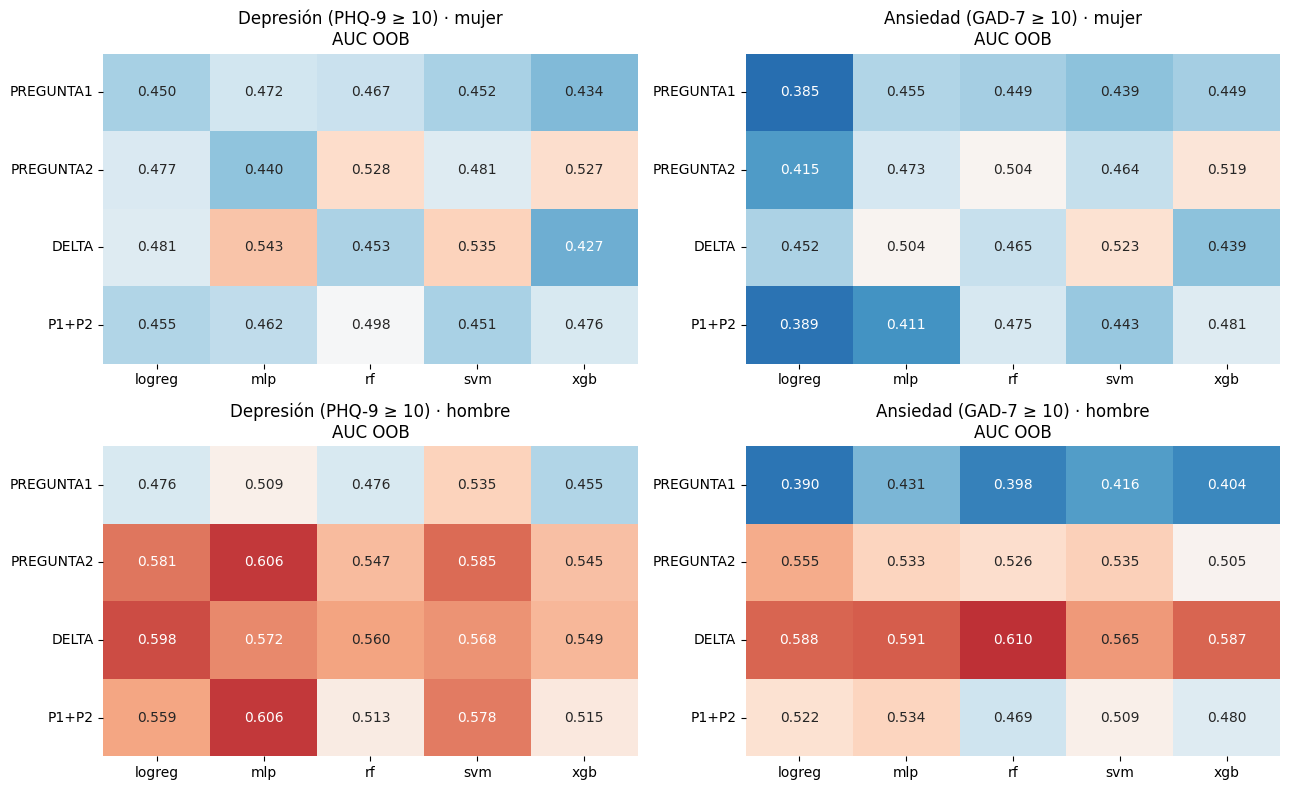

In [6]:
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
for i, s in enumerate(SEXOS):
    for j, (obj, nombre) in enumerate(OBJETIVOS.items()):
        t = modelos_voz[(modelos_voz["sexo"] == s) & (modelos_voz["objetivo"] == obj)]
        mapa = t.pivot(index="conjunto", columns="modelo", values="auc_oob").loc[list(CONJUNTOS)]
        sns.heatmap(mapa, annot=True, fmt=".3f", cmap="RdBu_r", center=0.5, vmin=0.35, vmax=0.65, ax=ax[i, j], cbar=False)
        ax[i, j].set_title(f"{nombre} · {s}\nAUC OOB"); ax[i, j].set_xlabel(""); ax[i, j].set_ylabel("")
plt.tight_layout(); plt.show()

AUC promedio de los 5 modelos por conjunto:

In [7]:
for col, nombre in [("auc_632", "AUC .632+"), ("auc_oob", "AUC OOB")]:
    print(f"{nombre}, media de los 5 modelos:")
    display(modelos_voz.groupby(["sexo", "objetivo", "conjunto"])[col].mean().unstack("conjunto")
            .reindex(SEXOS, level="sexo")[list(CONJUNTOS)].round(3))
print("Configuraciones con AUC .632+ > 0,5 y con AUC OOB > 0,5 en al menos el 80 % de las réplicas:")
display(modelos_voz.assign(sobre=modelos_voz["auc_632"] > 0.5, estable=modelos_voz["auc_oob_sobre_0.5"] >= 0.8)
        .groupby(["sexo", "objetivo"])[["sobre", "estable"]].sum().reindex(SEXOS, level="sexo")
        .rename(columns={"sobre": f"AUC .632+ > 0,5 (de {len(CONJUNTOS) * 5})", "estable": "OOB > 0,5 en ≥ 80 % de réplicas"}))

AUC .632+, media de los 5 modelos:


conjunto         PREGUNTA1  PREGUNTA2  DELTA  P1+P2
sexo   objetivo                                    
mujer  ans           0.500      0.507  0.509  0.500
       dep           0.500      0.517  0.523  0.500
hombre ans           0.500      0.546  0.624  0.520
       dep           0.514      0.604  0.599  0.578

AUC OOB, media de los 5 modelos:


conjunto         PREGUNTA1  PREGUNTA2  DELTA  P1+P2
sexo   objetivo                                    
mujer  ans           0.435      0.475  0.477  0.440
       dep           0.455      0.491  0.488  0.469
hombre ans           0.408      0.531  0.588  0.503
       dep           0.490      0.573  0.570  0.554

Configuraciones con AUC .632+ > 0,5 y con AUC OOB > 0,5 en al menos el 80 % de las réplicas:


AUC .632+ > 0,5 (de 20)  OOB > 0,5 en ≥ 80 % de réplicas
sexo   objetivo                                                          
mujer  ans                             4                                0
       dep                             4                                0
hombre ans                            13                                5
       dep                            17                                9

AUC aparente frente a OOB:

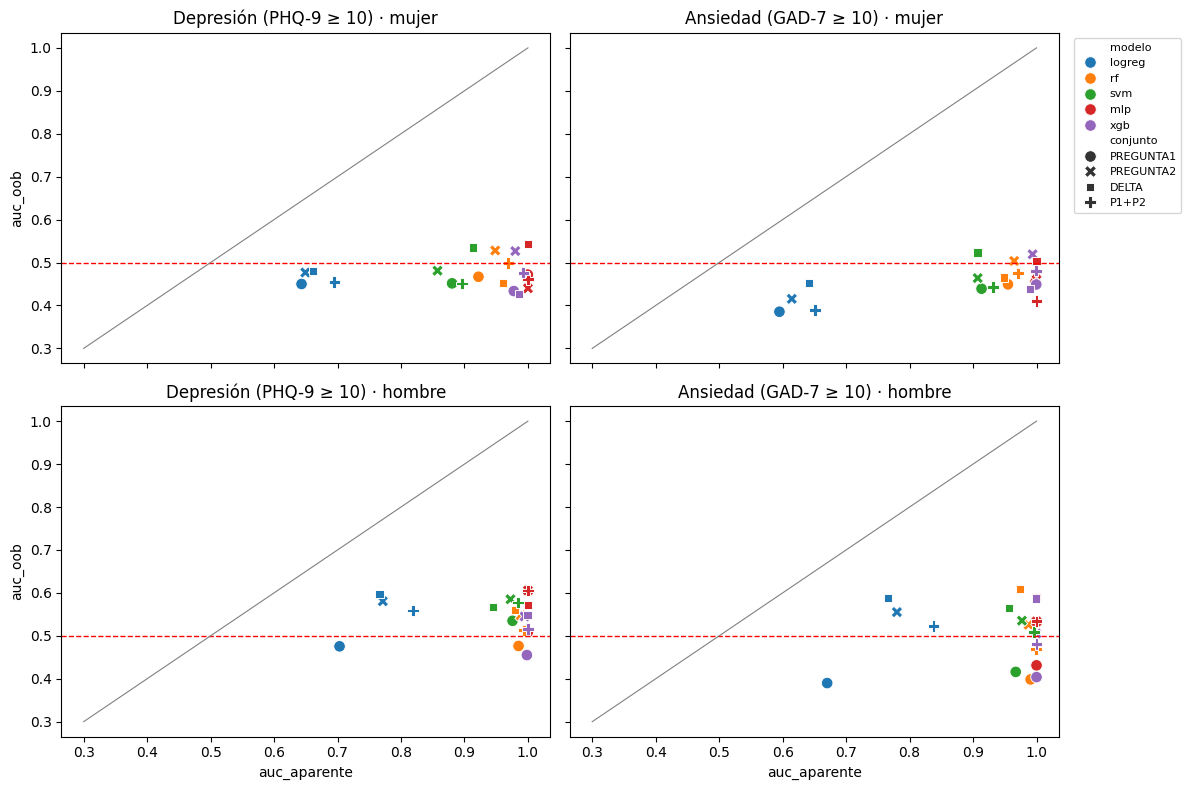

In [8]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
for i, s in enumerate(SEXOS):
    for j, (obj, nombre) in enumerate(OBJETIVOS.items()):
        t = modelos_voz[(modelos_voz["sexo"] == s) & (modelos_voz["objetivo"] == obj)]
        sns.scatterplot(data=t, x="auc_aparente", y="auc_oob", hue="modelo", style="conjunto", s=70, ax=ax[i, j],
                        legend=(i == 0 and j == 1))
        ax[i, j].axhline(0.5, color="red", ls="--", lw=1); ax[i, j].plot([0.3, 1], [0.3, 1], color="grey", lw=0.8)
        ax[i, j].set_title(f"{nombre} · {s}")
ax[0, 1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

## 4. Mejor configuración por desenlace y sexo

Mayor AUC .632+ (desempate por OOB). Matriz de confusión con la predicción OOB de cada sujeto (voto de las réplicas en que no salió sorteado):

==================== Depresión (PHQ-9 ≥ 10) · mujer: DELTA · mlp | sujetos con predicción OOB: 197 de 197
              precision    recall  f1-score   support

     no caso      0.558     0.530     0.544       100
        caso      0.539     0.567     0.553        97

    accuracy                          0.548       197
   macro avg      0.549     0.549     0.548       197
weighted avg      0.549     0.548     0.548       197

==================== Ansiedad (GAD-7 ≥ 10) · mujer: DELTA · svm | sujetos con predicción OOB: 197 de 197
              precision    recall  f1-score   support

     no caso      0.644     0.598     0.620       127
        caso      0.354     0.400     0.376        70

    accuracy                          0.528       197
   macro avg      0.499     0.499     0.498       197
weighted avg      0.541     0.528     0.534       197

==================== Depresión (PHQ-9 ≥ 10) · hombre: PREGUNTA2 · mlp | sujetos con predicción OOB: 158 de 158
              precision 

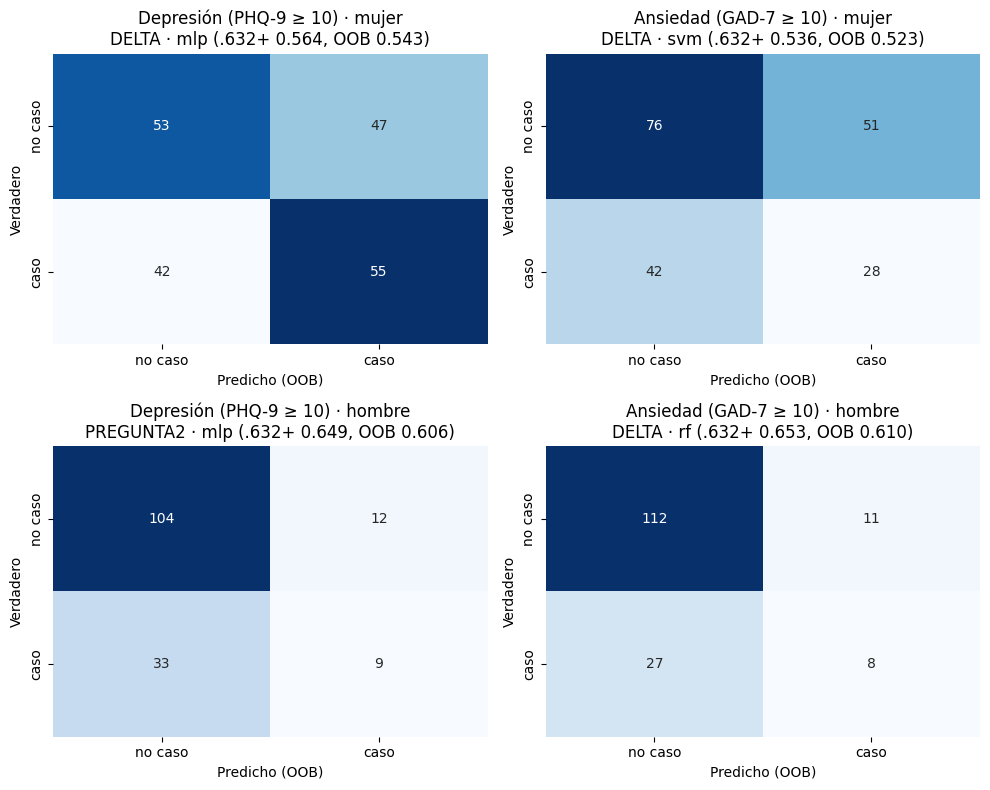

In [9]:
mejores = {}
fig, ax = plt.subplots(2, 2, figsize=(10, 8))
for i, s in enumerate(SEXOS):
    for j, (obj, nombre) in enumerate(OBJETIVOS.items()):
        t = modelos_voz[(modelos_voz["sexo"] == s) & (modelos_voz["objetivo"] == obj)]
        fila = t.sort_values(["auc_632", "auc_oob"], ascending=False).iloc[0]
        mejores[(s, obj)] = (fila["conjunto"], fila["modelo"])
        r = resultados[(s, obj, fila["conjunto"], fila["modelo"])]
        y = POR_SEXO[s][obj]
        con = ~np.isnan(r["oob_y"])
        cm = confusion_matrix(y[con], r["oob_y"][con].astype(int))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax[i, j], cbar=False,
                    xticklabels=["no caso", "caso"], yticklabels=["no caso", "caso"])
        ax[i, j].set_xlabel("Predicho (OOB)"); ax[i, j].set_ylabel("Verdadero")
        ax[i, j].set_title(f"{nombre} · {s}\n{fila['conjunto']} · {fila['modelo']} (.632+ {fila['auc_632']:.3f}, OOB {fila['auc_oob']:.3f})")
        print(f"==================== {nombre} · {s}: {fila['conjunto']} · {fila['modelo']} | sujetos con predicción OOB: {con.sum()} de {len(y)}")
        print(classification_report(y[con], r["oob_y"][con].astype(int), target_names=["no caso", "caso"], digits=3))
plt.tight_layout(); plt.show()

## 5. Guardar resultados

`predictivo_bootstrap.csv`: métricas OOB por réplica.

In [10]:
tabla.to_csv("outputs/predictivo_resumen.csv", index=False)
pd.DataFrame([{"sexo": s, "objetivo": o, "conjunto": c, "modelo": m, "replica": b,
               **{f"{k}_oob": v[b] for k, v in r["por_replica"].items()}}
              for (s, o, c, m), r in resultados.items() for b in range(N_BOOT)]
             ).to_csv("outputs/predictivo_bootstrap.csv", index=False)
print("Guardados: outputs/predictivo_resumen.csv, outputs/predictivo_bootstrap.csv")

Guardados: outputs/predictivo_resumen.csv, outputs/predictivo_bootstrap.csv


## 6. Test de permutación del mejor modelo

Se permutan las etiquetas dentro del sexo y se repite el bootstrap (`N_BOOT_PERM` réplicas). Estadístico: AUC OOB. Corte de Bonferroni para 4 tests: 0,0125. Con 100 permutaciones, el p mínimo es 1/101.

Depresión (PHQ-9 ≥ 10) · mujer · DELTA · mlp: AUC OOB 0.551 | nulo: media 0.503, p95 0.570 | p = 0.099 | 689 s


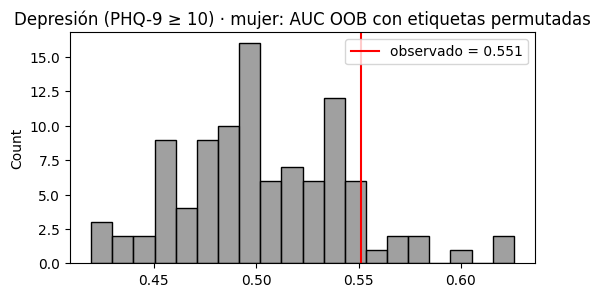

Ansiedad (GAD-7 ≥ 10) · mujer · DELTA · svm: AUC OOB 0.534 | nulo: media 0.501, p95 0.573 | p = 0.257 | 35 s


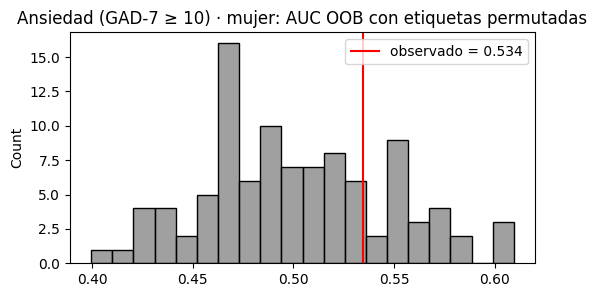

Depresión (PHQ-9 ≥ 10) · hombre · PREGUNTA2 · mlp: AUC OOB 0.613 | nulo: media 0.503, p95 0.588 | p = 0.010 | 507 s


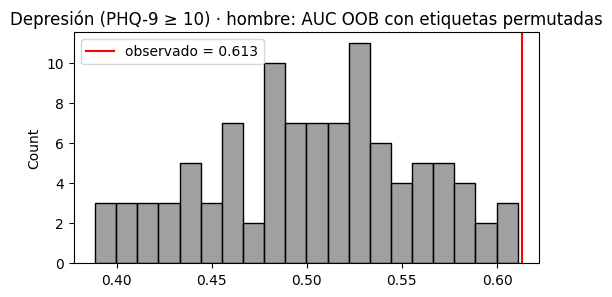

Ansiedad (GAD-7 ≥ 10) · hombre · DELTA · rf: AUC OOB 0.617 | nulo: media 0.494, p95 0.589 | p = 0.040 | 853 s


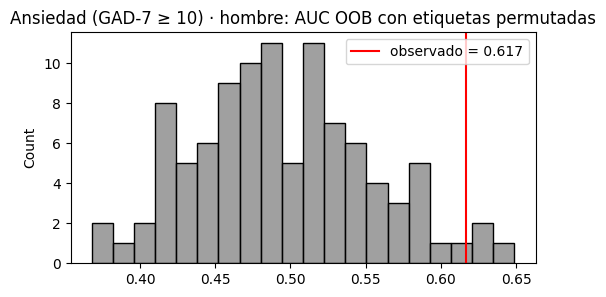

In [11]:
filas_perm = []
if N_PERMUTACIONES > 0:
    rng = np.random.default_rng(SEMILLA)
    for (s, obj), (conj, mod) in mejores.items():
        d_s = POR_SEXO[s]
        est, X, y = pipeline(modelos(d_s[obj])[mod]), d_s[CONJUNTOS[conj]], d_s[obj]
        t0 = time.time()
        auc = evaluar(est, X, y, n_boot=N_BOOT_PERM)["oob"]["auc"]
        auc_perm = np.array([evaluar(est, X, pd.Series(rng.permutation(y.values)), n_boot=N_BOOT_PERM)["oob"]["auc"]
                             for _ in range(N_PERMUTACIONES)])
        p = (1 + (auc_perm >= auc).sum()) / (N_PERMUTACIONES + 1)
        anotar(f"{OBJETIVOS[obj]} · {s} · {conj} · {mod}: AUC OOB {auc:.3f} | nulo: media {auc_perm.mean():.3f}, "
               f"p95 {np.percentile(auc_perm, 95):.3f} | p = {p:.3f} | {time.time() - t0:.0f} s")
        filas_perm.append({"sexo": s, "objetivo": obj, "conjunto": conj, "modelo": mod, "auc_oob": auc,
                           "nulo_media": auc_perm.mean(), "nulo_p95": np.percentile(auc_perm, 95), "p": p,
                           "permutaciones": N_PERMUTACIONES, "replicas_bootstrap": N_BOOT_PERM})
        pd.DataFrame(filas_perm).to_csv("outputs/predictivo_permutacion.csv", index=False)
        plt.figure(figsize=(6, 3))
        sns.histplot(auc_perm, bins=20, color="grey")
        plt.axvline(auc, color="red", label=f"observado = {auc:.3f}")
        plt.title(f"{OBJETIVOS[obj]} · {s}: AUC OOB con etiquetas permutadas"); plt.legend(); plt.show()

## 7. Prueba final (sellada)

Se usa una sola vez, con un modelo ya elegido. El modelo se ajusta con todo desarrollo de ese sexo; la prueba final recibe el mismo tratamiento de valores extremos (`outputs/limites_outliers.csv`) y el DELTA se calcula después.

In [12]:
EVALUAR_PRUEBA_FINAL = False
MODELO_FINAL = None   # p. ej. ("mujer", "dep", "DELTA", "svm")

if EVALUAR_PRUEBA_FINAL:
    s, obj, conj, mod = MODELO_FINAL
    feat = pd.read_csv("../feature-extraction-UA/outputs/features_core_completos.csv", dtype={"participant_id": str})
    prueba_ids = pd.read_csv("prueba_final_ids.csv", dtype={"participant_id": str})["participant_id"]
    feat = feat[feat["participant_id"].isin(prueba_ids) & feat["task"].isin(["PREGUNTA1", "PREGUNTA2"])]
    ancha = feat.pivot(index="participant_id", columns="task", values=FEATURES)
    ancha.columns = [f"{f}__{t}" for f, t in ancha.columns]
    etq = pd.read_excel("../baseDatos_tabular.xlsx")
    etq["participant_id"] = etq["cualestucodigo"].astype(int).astype(str).str.zfill(3)
    etq["dep"], etq["ans"] = (etq["TOTALPHQ9"] >= 10).astype(int), (etq["TOTALGAD7"] >= 10).astype(int)
    etq["sexo"] = etq["SEXO"].map({1: "mujer", 2: "hombre"})
    prueba = etq.set_index("participant_id")[["dep", "ans", "sexo"]].join(ancha, how="inner")
    prueba = prueba[prueba["sexo"] == s].copy()
    # Mismos límites que en desarrollo
    limites = pd.read_csv("outputs/limites_outliers.csv")
    for _, lim in limites[limites["sexo"] == s].iterrows():
        c = lim["columna"]
        if lim["tratamiento"] == "recortar":
            prueba[c] = prueba[c].clip(lim["p_inf"], lim["p_sup"])
        else:
            prueba.loc[(prueba[c] < lim["p_inf"]) | (prueba[c] > lim["p_sup"]), c] = np.nan
    for f in FEATURES:
        prueba[f"{f}__DELTA"] = prueba[f"{f}__PREGUNTA2"] - prueba[f"{f}__PREGUNTA1"]
    d_s = POR_SEXO[s]
    final = pipeline(modelos(d_s[obj])[mod]).fit(d_s[CONJUNTOS[conj]], d_s[obj])
    p = puntaje(final, prueba[CONJUNTOS[conj]])
    print(f"Prueba final · {s} (n = {len(prueba)}, casos = {prueba[obj].sum()}): AUC = {roc_auc_score(prueba[obj], p):.3f}")
    print(classification_report(prueba[obj], final.predict(prueba[CONJUNTOS[conj]]), digits=3))
else:
    print("Prueba final sellada: no se evaluó.")

Prueba final sellada: no se evaluó.


## Lectura de resultados

**Referencia**: AUC 0,500 en los cuatro grupos.

**AUC .632+ promedio de los 5 modelos**

| | PREGUNTA1 | PREGUNTA2 | DELTA | P1+P2 |
|---|---|---|---|---|
| Mujeres, depresión | 0,500 | 0,517 | 0,523 | 0,500 |
| Mujeres, ansiedad | 0,500 | 0,507 | 0,509 | 0,500 |
| Hombres, depresión | 0,514 | 0,604 | 0,599 | 0,578 |
| Hombres, ansiedad | 0,500 | 0,546 | 0,624 | 0,520 |

**Mujeres**
- AUC OOB promedio entre 0,435 y 0,491 en todos los conjuntos; 4 de 20 configuraciones superan 0,5 en .632+ por desenlace.
- Mejores: MLP con DELTA en depresión (.632+ 0,564; permutación p = 0,099) y SVM con DELTA en ansiedad (0,536; p = 0,257).
- Las features no predicen depresión ni ansiedad.

**Hombres**
- Ansiedad, DELTA: los 5 modelos entre 0,595 y 0,653 (.632+) y entre 0,565 y 0,610 (OOB). Mejor: bosque, .632+ 0,653, permutación p = 0,040.
- Depresión: PREGUNTA2 y DELTA rinden parecido (0,604 y 0,599). Mejor: MLP con PREGUNTA2, .632+ 0,649, permutación p = 0,010 (ninguna de 100 permutaciones lo igualó).
- PREGUNTA1 no aporta (0,500 y 0,514).
- Como clasificadores son débiles: exactitud balanceada OOB de 0,52 a 0,57. Bosque y MLP detectan pocos casos (sensibilidad 0,23–0,27); la logística reparte mejor (0,47–0,49 y especificidad 0,62–0,65).

**Cautelas**
- Cada mejor modelo es el mayor de 20 configuraciones: su p es optimista. Solo hombres · depresión pasa 0,0125.
- 42 y 35 casos en hombres; el AUC OOB varía ± 0,07 entre réplicas.
- Lo de hombres no se repite en mujeres.
- 29 de los 35 hombres con ansiedad también tienen depresión: los dos desenlaces no son evidencia independiente.

**Resumen**: en mujeres no hay señal. En hombres, PREGUNTA2 y DELTA dan un AUC cercano a 0,6 en ambos desenlaces; es exploratorio y débil como clasificador. Falta decidir si se fija un modelo para la prueba final.